In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors as mcolors
from pathlib import Path

In [2]:
data_path = Path.cwd().parent / "data/processed"
fig_path = Path.cwd().parent / "figures"
fig_path.mkdir(exist_ok=True)

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

In [3]:
surf = pd.read_pickle(data_path / "surface_clean.pkl")
preds = pd.read_pickle(data_path / "surface_preds.pkl")
TENORS = list(surf.columns.unique("tenor"))
MONEYNESS = list(surf.columns.unique("moneyness"))

prev = surf.shift(1).reindex(preds["persistence"].index)
assert np.allclose(preds["persistence"].dropna(), prev.loc[preds["persistence"].dropna().index])
real = surf.reindex(preds["persistence"].index)
ok = real.notna().all(axis=1) & pd.concat([p.notna().all(axis=1) for p in preds.values()], axis=1).all(axis=1)
real = real[ok]
errors = {name: (p[ok] - real) for name, p in preds.items()}
print(f"Days: {ok.sum()} ({real.index[0]:%Y-%m-%d} to {real.index[-1]:%Y-%m-%d})")

Days: 1444 (2021-01-04 to 2026-10-07)


In [4]:
gain = errors["persistence"].abs().mean(axis=1) - errors["cnn_conv_head"].abs().mean(axis=1)
move = (real - prev[ok]).abs().mean(axis=1)
days = {
    "largest move": move.idxmax(),
    "largest CNN loss": gain.idxmin(),
    "typical day": (move - move.median()).abs().idxmin(),
    "last day": real.index[-1],
}
pd.DataFrame({
    "date": [d.date() for d in days.values()],
    "mean abs move": [move[d] for d in days.values()],
    "MAE persistence": [errors["persistence"].loc[d].abs().mean() for d in days.values()],
    "MAE CNN": [errors["cnn_conv_head"].loc[d].abs().mean() for d in days.values()],
}, index=list(days)).round(3)

,date,mean abs move,MAE persistence,MAE CNN
largest move,2025-04-09,6.271,6.271,4.776
largest CNN loss,2025-04-08,1.660,1.660,2.904
typical day,2023-03-31,0.303,0.303,0.333
last day,2026-10-07,0.171,0.171,0.164


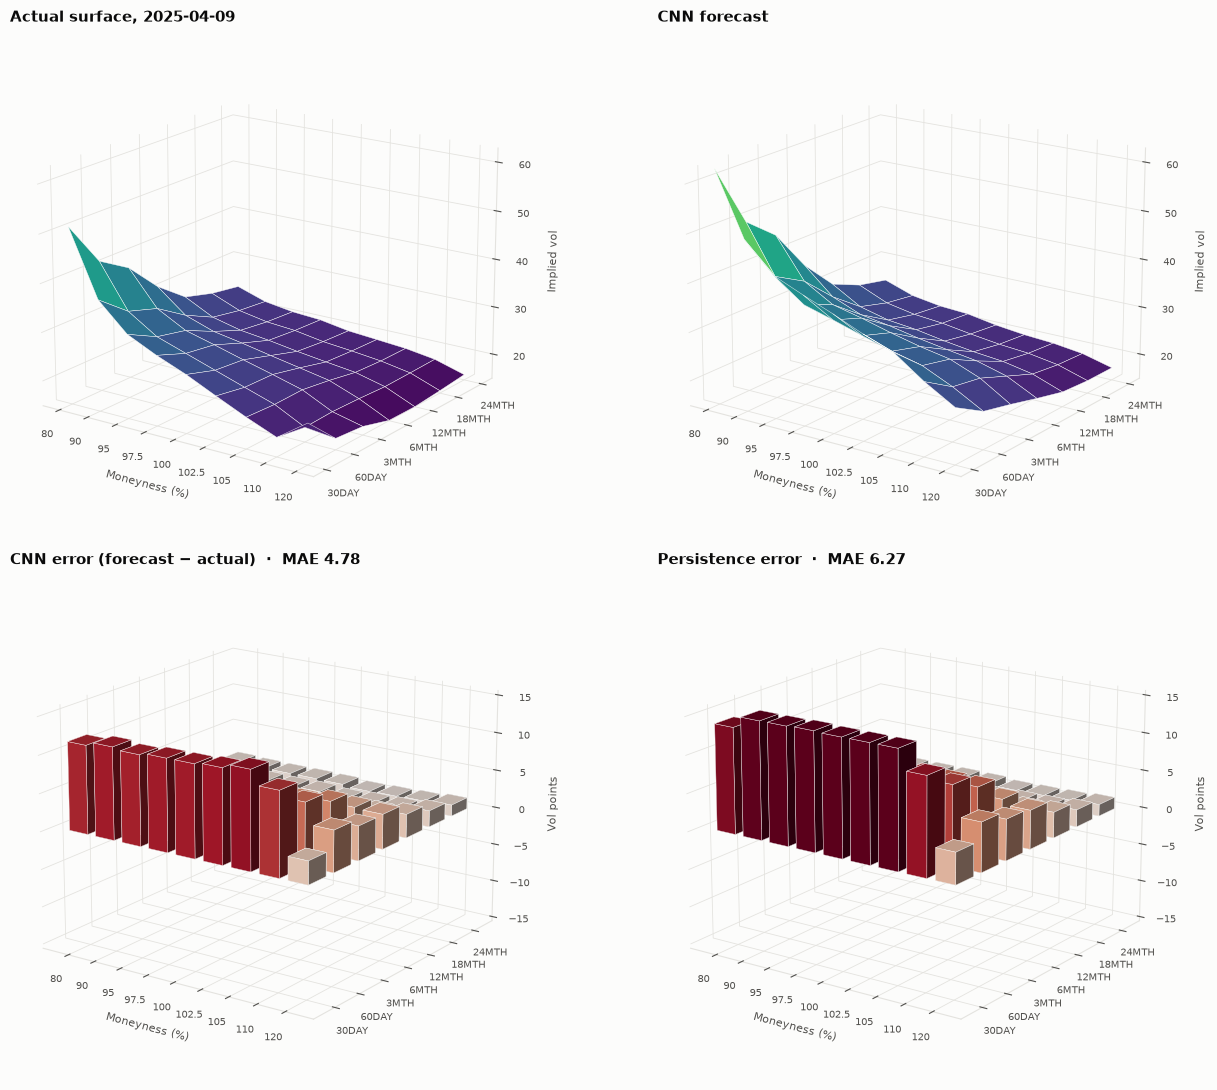

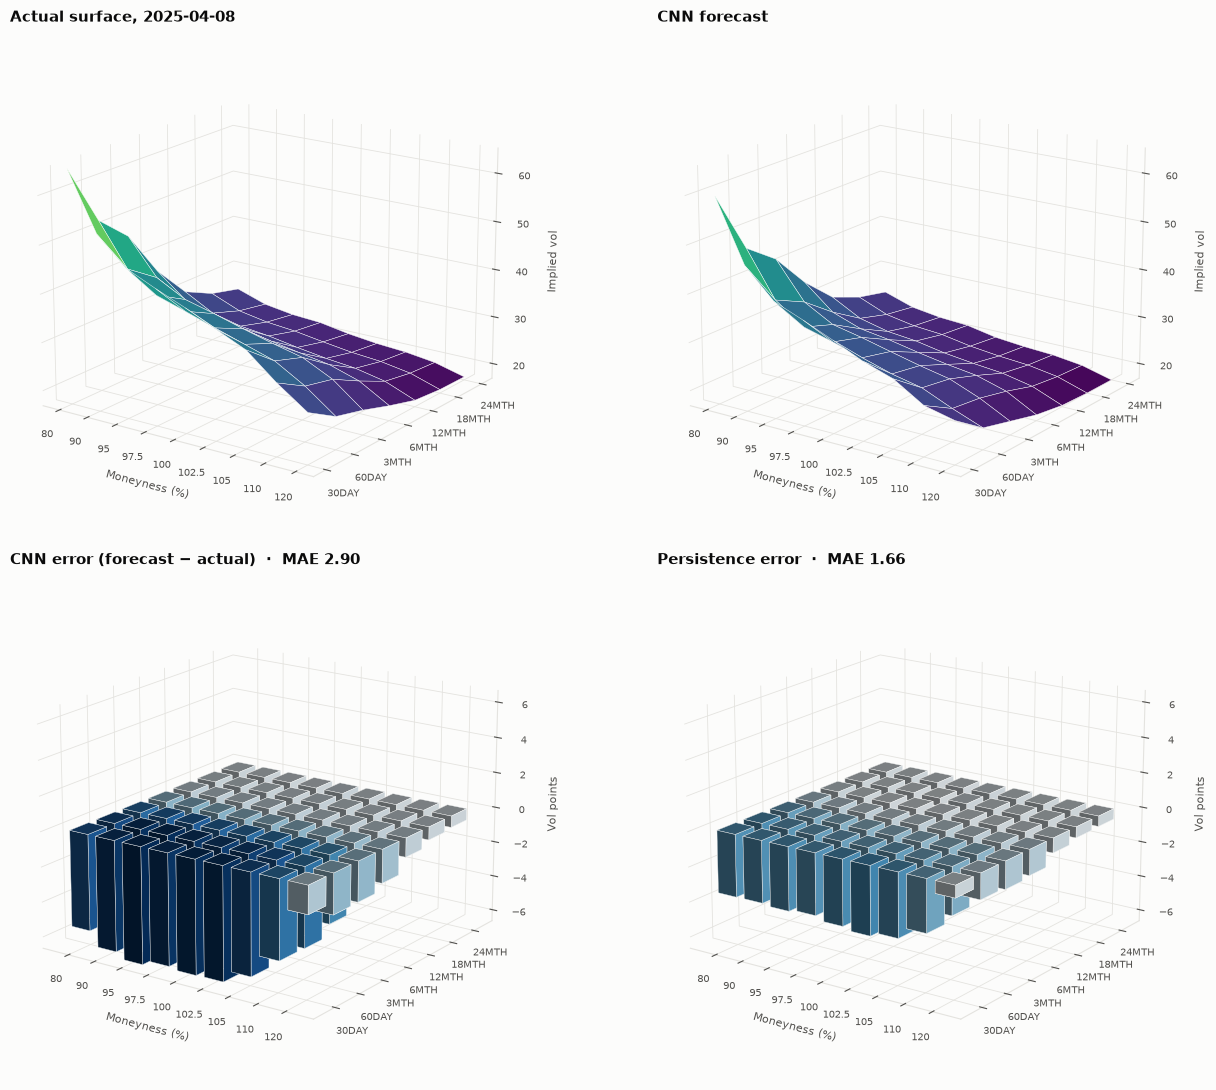

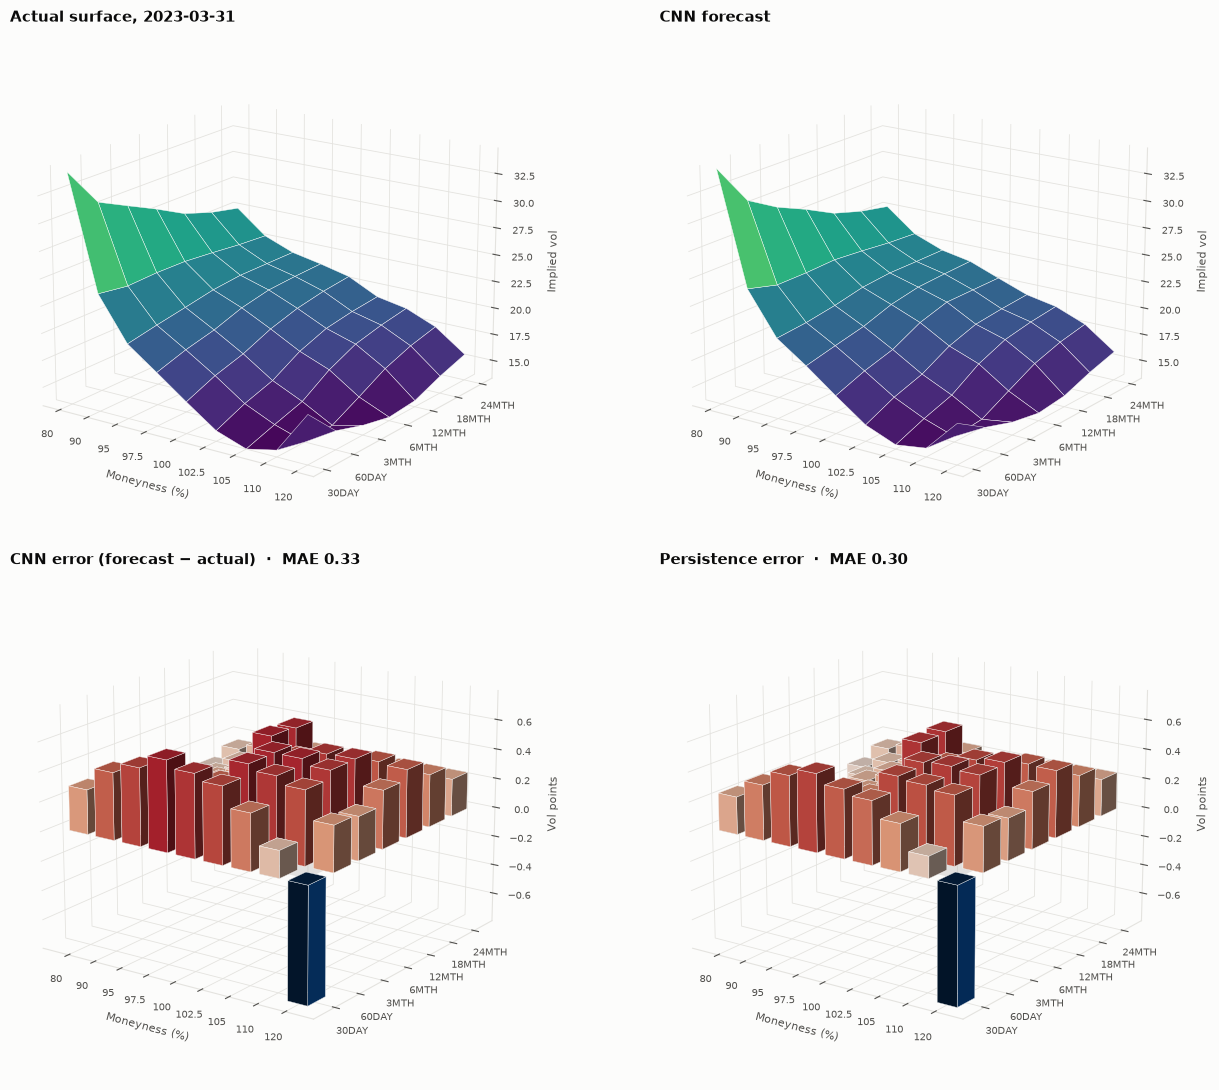

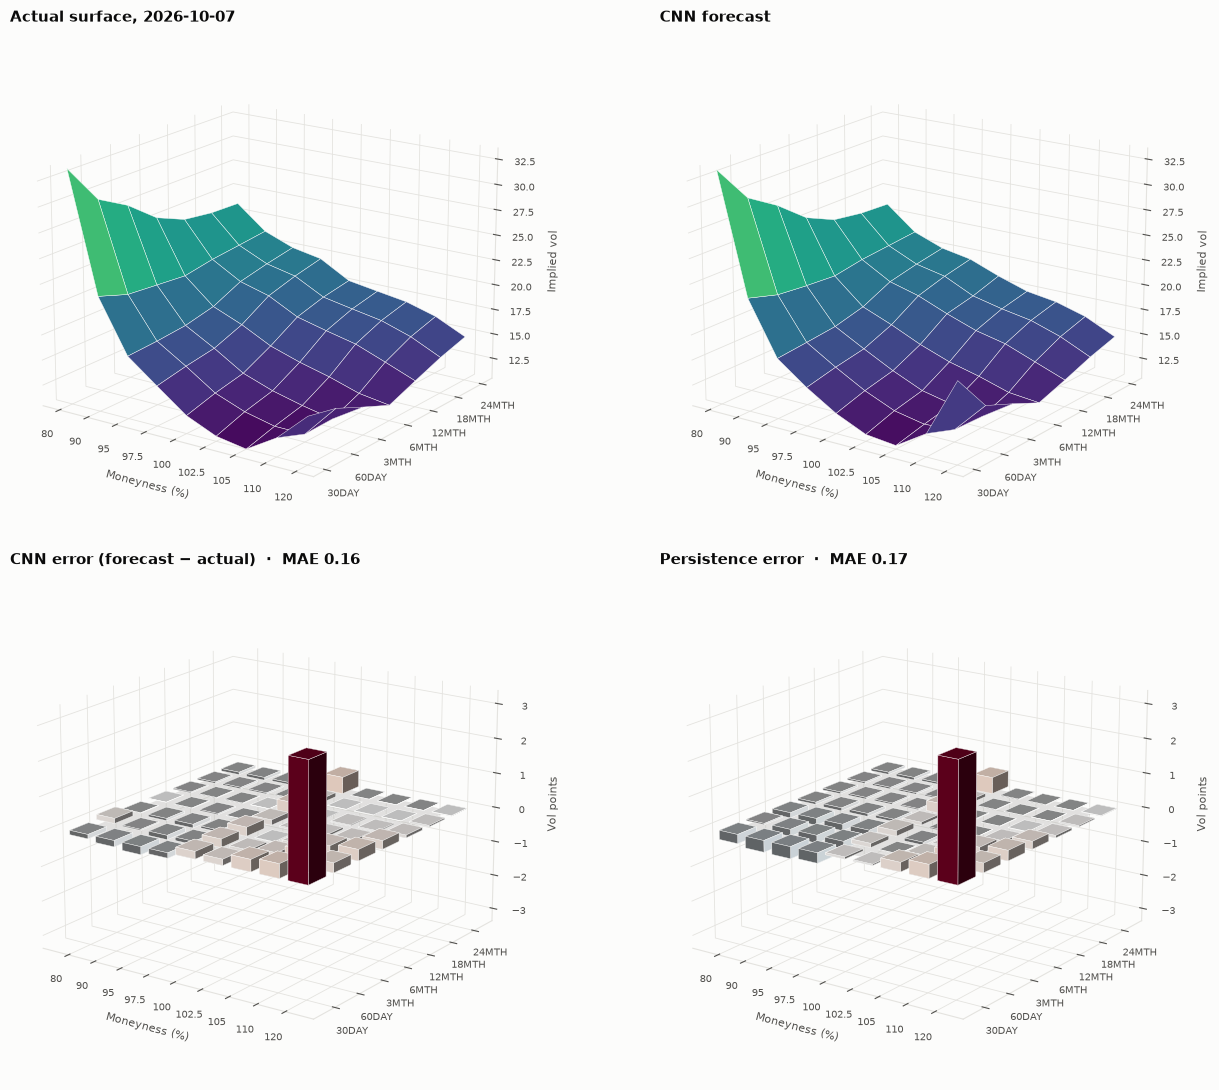

In [5]:
X, Y = np.meshgrid(np.arange(len(MONEYNESS)), np.arange(len(TENORS)))


def grid(row):
    return row.unstack().loc[TENORS, MONEYNESS].to_numpy()


def style_3d(ax, title, zlabel):
    ax.set_xticks(range(len(MONEYNESS)), [f"{m:g}" for m in MONEYNESS], fontsize=7)
    ax.set_yticks(range(len(TENORS)), TENORS, fontsize=7)
    ax.set_xlabel("Moneyness (%)", fontsize=8)
    ax.set_zlabel(zlabel, fontsize=8)
    ax.tick_params(axis="z", labelsize=7)
    ax.set_title(title, loc="left", fontsize=11)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color(SURFACE)
        axis._axinfo["grid"]["color"] = GRID
    ax.view_init(elev=18, azim=-55)


def plot_surface_day(day, model="cnn_conv_head"):
    r, f = grid(real.loc[day]), grid(preds[model].loc[day])
    e_model, e_rw = grid(errors[model].loc[day]), grid(errors["persistence"].loc[day])
    vmin, vmax = min(r.min(), f.min()), max(r.max(), f.max())
    emax = max(np.abs(e_model).max(), np.abs(e_rw).max())
    norm = mcolors.TwoSlopeNorm(0, -emax, emax)
    fig = plt.figure(figsize=(14, 11))
    for k, (z, title) in enumerate([(r, f"Actual surface, {day:%Y-%m-%d}"), (f, "CNN forecast")]):
        ax = fig.add_subplot(2, 2, k + 1, projection="3d")
        ax.plot_surface(X, Y, z, cmap="viridis", vmin=vmin, vmax=vmax, edgecolor=SURFACE, linewidth=0.3)
        ax.set_zlim(vmin, vmax)
        style_3d(ax, title, "Implied vol")
    for k, (e, title) in enumerate([(e_model, "CNN error (forecast − actual)"), (e_rw, "Persistence error")]):
        ax = fig.add_subplot(2, 2, k + 3, projection="3d")
        ax.bar3d(X.ravel() - 0.35, Y.ravel() - 0.35, 0, 0.7, 0.7, e.ravel(),
                 color=cm.RdBu_r(norm(e.ravel())), edgecolor=SURFACE, linewidth=0.3, shade=True)
        ax.plot_surface(X, Y, np.zeros_like(X, dtype=float), color=GRID, alpha=0.35, linewidth=0)
        ax.set_zlim(-emax, emax)
        style_3d(ax, f"{title}  ·  MAE {np.abs(e).mean():.2f}", "Vol points")
    plt.tight_layout()
    return fig


for label, day in days.items():
    fig = plot_surface_day(day)
    fig.savefig(fig_path / f"surface_forecast_{day:%Y%m%d}.png", dpi=150, bbox_inches="tight")
    plt.show()

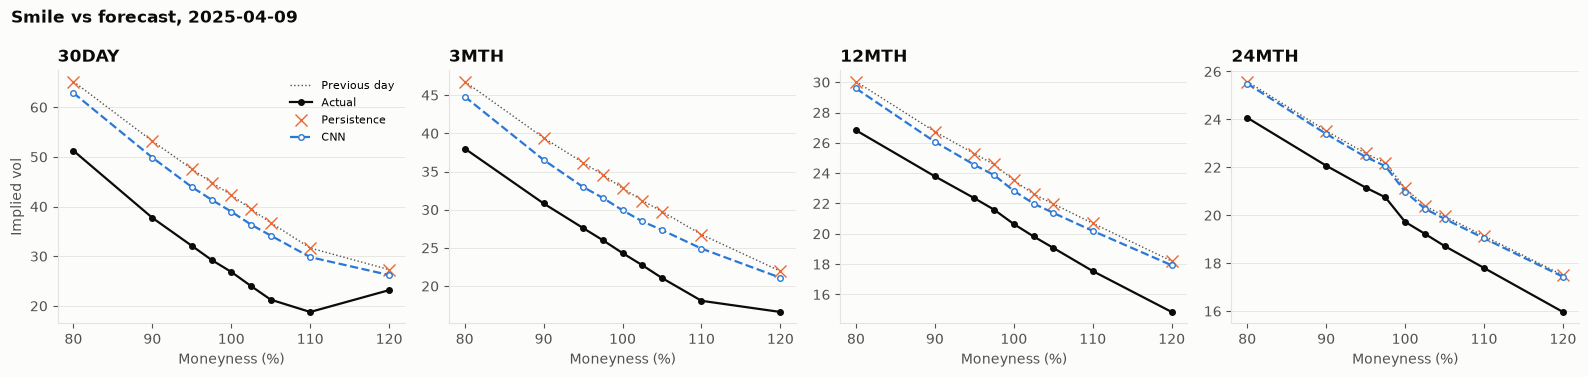

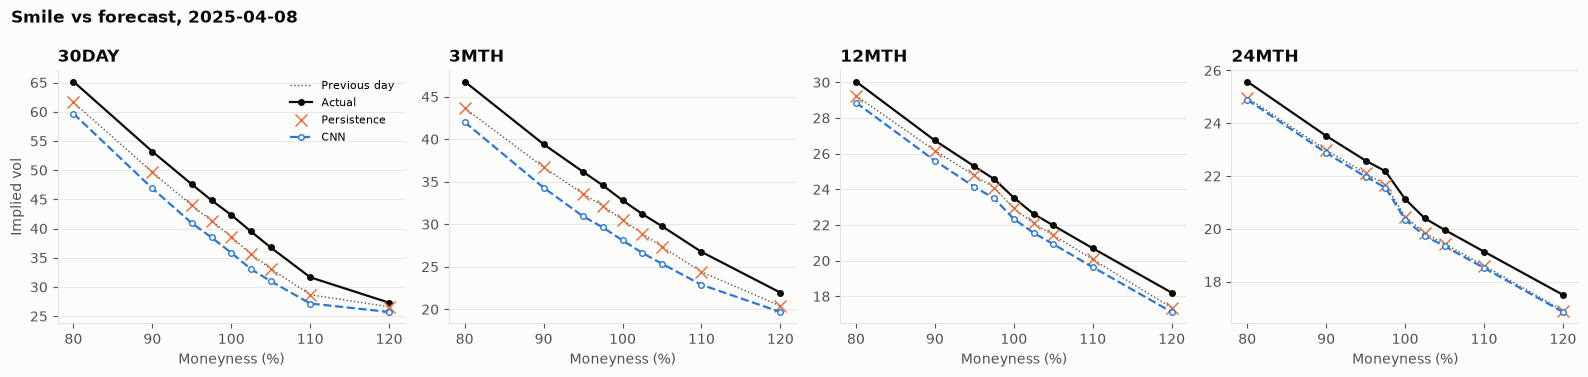

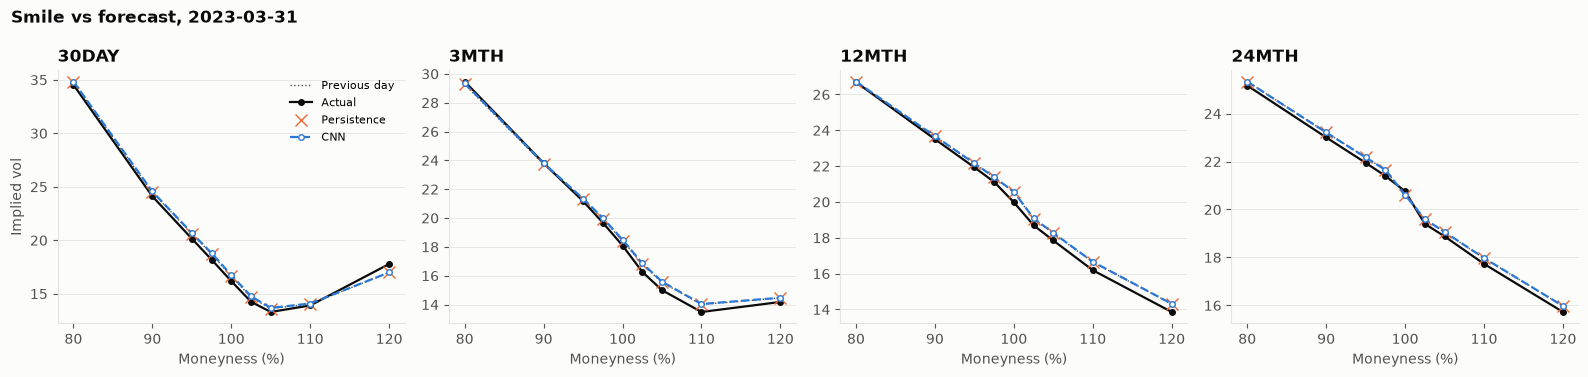

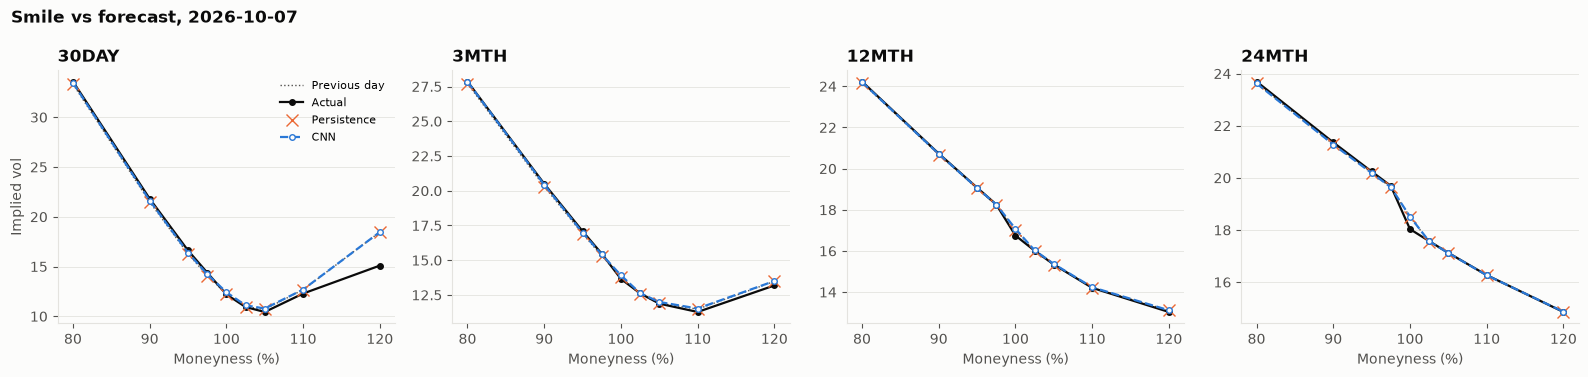

In [6]:
SMILE_TENORS = ["30DAY", "3MTH", "12MTH", "24MTH"]


def plot_smiles(day, model="cnn_conv_head"):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
    for ax, t in zip(axes, SMILE_TENORS):
        ax.plot(MONEYNESS, prev.loc[day, t], color=INK_2, lw=1, ls=":", label="Previous day")
        ax.plot(MONEYNESS, real.loc[day, t], color=INK, marker="o", ms=4, label="Actual")
        ax.plot(MONEYNESS, preds["persistence"].loc[day, t], color=COLORS[1], lw=0, marker="x", ms=8, label="Persistence")
        ax.plot(MONEYNESS, preds[model].loc[day, t], color=COLORS[0], ls="--", marker="o", ms=4, mfc=SURFACE, label="CNN")
        ax.set_title(t)
        ax.set_xlabel("Moneyness (%)")
    axes[0].set_ylabel("Implied vol")
    axes[0].legend(fontsize=8)
    fig.suptitle(f"Smile vs forecast, {day:%Y-%m-%d}", x=0.01, ha="left", fontweight="bold", color=INK)
    plt.tight_layout()
    return fig


for label, day in days.items():
    plot_smiles(day)
    plt.show()